# Expérimentations préliminaires — 0. Données et protocole

Jeu de données commun aux trois modèles (régression logistique, XGBoost, LSTM) et protocole
d'évaluation. Ce notebook ne contient aucun modèle : il produit les tableaux descriptifs du
rapport (données, plis, valeurs manquantes, redondance des variables).

**Protocole commun** (voir `src/nhl_forecast/features/equipes.py` et
`src/nhl_forecast/evaluation/preliminaire.py`) :

- saisons régulières 2020-21 à 2025-26, statistiques d'**équipes** seulement, **toutes les
  colonnes** de `t_summary`, `t_percentages`, `t_summaryshooting`, `t_outshootoutshotby` et
  MoneyPuck (5 situations de jeu) ; seuls les identifiants, les colonnes vides ou constantes et
  les doublons exacts sont retirés, automatiquement ;
- validation croisée **chronologique** à 5 plis (fenêtre croissante) : le pli *k* entraîne sur
  les saisons 1 à *k* et teste sur la saison *k* + 1 ;
- hyperparamètres choisis sur les 20 % les plus récents des matchs d'entraînement du pli ;
- métriques : log loss, score de Brier, accuracy (seuil 0,5).

Avec `SAUVER = True`, les tableaux sont enregistrés en CSV (séparateur « ; ») dans
`reports/map6009/tables/` (préfixe `exp_`) et les prédictions dans
`data/processed/experimentation/` (lues par `04_comparaison.ipynb`).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from nhl_forecast.evaluation.preliminaire import (
    FIG_DIR,
    exporter_tableau,
    formater,
    plis_chronologiques,
    tableau_plis,
)
from nhl_forecast.features.equipes import (
    FENETRE,
    NOM_SAISON,
    SEP,
    bilan_colonnes,
    charger_equipes,
    colonnes_stats,
    construire_matchs,
    variables,
)
from nhl_forecast.visualization.style import ENCRE, appliquer_style

SAUVER = True
appliquer_style()

In [3]:
eq = charger_equipes()          # une équipe-match par ligne (valeurs du match)
matchs = construire_matchs(eq)  # un match par ligne, variables d'avant-match
STATS = colonnes_stats(eq)
X_cols = variables(matchs)
print(f"{len(eq)} équipes-matchs, {len(matchs)} matchs, {len(STATS)} statistiques, "
      f"{len(X_cols)} variables explicatives")

14856 équipes-matchs, 7428 matchs, 525 statistiques, 1052 variables explicatives


C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:182: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


## 1. Variables

Toutes les colonnes numériques des cinq sources sont utilisées (aucune sélection manuelle).
Pour MoneyPuck, chaque statistique est prise dans les cinq situations de jeu (`all`, `5on5`,
`5on4`, `4on5`, `other`). Retraits automatiques : colonnes vides ou constantes (ex.
`gamesPlayed`, toujours 1) et doublons exacts (ex. `pointPct`, présent dans plusieurs
rapports de la LNH).

Pour chaque statistique, deux variables **d'avant-match** :

- `_saison` : moyenne des matchs précédents de la saison ;
- `_10` : moyenne des 10 derniers matchs (forme récente / momentum, au moins 3 matchs).

S'y ajoutent les jours de repos et le nombre de matchs joués. Chaque variable de match est
l'écart **local − visiteur** (préfixe `d_`). Le décalage d'un match appliqué avant toute
moyenne garantit qu'aucune statistique du match à prédire n'est utilisée.

In [5]:
NOMS_SOURCES = {
    "summary": "LNH – t_summary", "percentages": "LNH – t_percentages",
    "summaryshooting": "LNH – t_summaryshooting", "outshootoutshotby": "LNH – t_outshootoutshotby",
    "mp_all": "MoneyPuck – all", "mp_5on5": "MoneyPuck – 5on5", "mp_5on4": "MoneyPuck – 5on4",
    "mp_4on5": "MoneyPuck – 4on5", "mp_other": "MoneyPuck – other",
}
tab_sources = bilan_colonnes()
tab_sources["Retirées"] = tab_sources["Colonnes numériques"] - tab_sources["Retenues"]
tab_sources["Source"] = pd.Categorical(tab_sources["Source"].map(NOMS_SOURCES),
                                       list(NOMS_SOURCES.values()), ordered=True)
tab_sources = tab_sources.sort_values("Source")
tab_sources["Source"] = tab_sources["Source"].astype(str)
tab_sources.loc[len(tab_sources)] = ["Contexte (repos, matchs joués)", 2, 2, 0]
tot = tab_sources.drop(columns="Source").sum()
tab_sources.loc[len(tab_sources)] = ["Total", *tot.astype(int)]
tab_sources = tab_sources[["Source", "Colonnes numériques", "Retirées", "Retenues"]]
tab_vars = pd.DataFrame([c.split(SEP) for c in STATS], columns=["Source", "Statistique"])
tab_vars["Source"] = tab_vars["Source"].map(NOMS_SOURCES)
if SAUVER:
    exporter_tableau(tab_sources, "exp_sources")
    exporter_tableau(tab_vars, "exp_variables")  # liste complète des statistiques retenues
formater(tab_sources)

Source,Colonnes numériques,Retirées,Retenues
LNH – t_summary,21,4,17
LNH – t_percentages,18,3,15
LNH – t_summaryshooting,16,1,15
LNH – t_outshootoutshotby,22,12,10
MoneyPuck – all,100,2,98
MoneyPuck – 5on5,100,0,100
MoneyPuck – 5on4,100,10,90
MoneyPuck – 4on5,100,10,90
MoneyPuck – other,100,10,90
"Contexte (repos, matchs joués)",2,0,2


## 2. Matchs par saison

In [7]:
tab_saisons = (
    matchs.groupby("saison")
    .agg(Matchs=("gameId", "size"), Victoires_locales=("victoire_locale", "mean"),
         Debut=("date", "min"), Fin=("date", "max"))
    .reset_index()
)
tab_saisons["saison"] = tab_saisons["saison"].map(NOM_SAISON)
tab_saisons[["Debut", "Fin"]] = tab_saisons[["Debut", "Fin"]].apply(lambda s: s.dt.strftime("%Y-%m-%d"))
tab_saisons = tab_saisons.rename(columns={"saison": "Saison", "Victoires_locales": "% victoires locales",
                                          "Debut": "Début"})
if SAUVER:
    exporter_tableau(tab_saisons, "exp_saisons")
formater(tab_saisons, 3)

Saison,Matchs,% victoires locales,Début,Fin
2020-21,868,0.533,2021-01-13,2021-05-19
2021-22,1312,0.537,2021-10-12,2022-05-01
2022-23,1312,0.524,2022-10-07,2023-04-14
2023-24,1312,0.541,2023-10-10,2024-04-18
2024-25,1312,0.562,2024-10-04,2025-04-17
2025-26,1312,0.522,2025-10-07,2026-04-16


La saison 2020-21 (pandémie) ne compte que 56 matchs par équipe, joués à huis clos en grande
partie : l'avantage de la glace y est plus faible. Elle ne sert qu'à l'entraînement.

## 3. Plis chronologiques

Fenêtre croissante, une saison testée par pli. La date maximale d'entraînement est toujours
antérieure à la date minimale de test (vérifié par `assert` dans `plis_chronologiques`).

In [8]:
tab_plis = tableau_plis(matchs)
if SAUVER:
    exporter_tableau(tab_plis, "exp_plis")
formater(tab_plis)

Pli,Saisons d'entraînement,Saison testée,Matchs (entraînement),dont validation interne,Matchs (test)
1,2020-21 à 2020-21,2021-22,868,174,1312
2,2020-21 à 2021-22,2022-23,2180,436,1312
3,2020-21 à 2022-23,2023-24,3492,698,1312
4,2020-21 à 2023-24,2024-25,4804,961,1312
5,2020-21 à 2024-25,2025-26,6116,1223,1312


## 4. Valeurs manquantes

Deux origines :

- **début de saison** : aucune moyenne au premier match d'une équipe, aucune forme récente
  avant son 4e match, pas de jours de repos au premier match ;
- **statistiques non définies** pour certains matchs (ex. % en avantage numérique sans
  avantage numérique, % de tirs quand le score est serré si le match ne l'a jamais été).

Traitement retenu (ajusté sur l'entraînement du pli seulement) :

- régression logistique : imputation par la médiane, puis standardisation et ACP ;
- XGBoost : gestion native des NaN (direction par défaut apprise à chaque nœud) ;
- LSTM : imputation par la médiane des équipes-matchs, standardisation et ACP ; séquences
  plus courtes que 20 rembourrées par des 0 et masquées.

In [9]:
groupes = {
    "Moyenne de la saison (_saison)": [c for c in X_cols if c.endswith("_saison")],
    f"Forme récente (_{FENETRE})": [c for c in X_cols if c.endswith(f"_{FENETRE}")],
    "Jours de repos": ["d_repos"],
}
lignes = []
for nom, cols in groupes.items():
    manq = matchs[cols].isna()
    lignes.append({"Groupe de variables": nom, "Variables": len(cols),
                   "% des valeurs manquantes": 100 * manq.to_numpy().mean(),
                   "% matchs avec ≥ 1 manquant": 100 * manq.any(axis=1).mean()})
manq_tout = matchs[X_cols].isna()
lignes.append({"Groupe de variables": "Toutes", "Variables": len(X_cols),
               "% des valeurs manquantes": 100 * manq_tout.to_numpy().mean(),
               "% matchs avec ≥ 1 manquant": 100 * manq_tout.any(axis=1).mean()})
tab_manq = pd.DataFrame(lignes)
if SAUVER:
    exporter_tableau(tab_manq, "exp_manquants", 2)
formater(tab_manq, 2)

Groupe de variables,Variables,% des valeurs manquantes,% matchs avec ≥ 1 manquant
Moyenne de la saison (_saison),525,1.60,3.45
Forme récente (_10),525,4.35,10.06
Jours de repos,1,1.59,1.59
Toutes,1052,2.97,10.06


In [10]:
# Où se trouvent les manquants : selon le nombre de matchs déjà joués par l'équipe locale
joues = eq.groupby(["saison", "teamId"]).cumcount()
eq_loc = eq.assign(joues=joues)[eq["domicile"] == 1][["gameId", "joues"]]
tranche = pd.cut(matchs.merge(eq_loc, on="gameId")["joues"], [-1, 0, 2, 9, 200],
                 labels=["1er match", "2e-3e", "4e-10e", "11e et +"])
part = manq_tout.mean(axis=1)
tab_manq_debut = (pd.DataFrame({"tranche": tranche.to_numpy(), "part": 100 * part.to_numpy()})
                  .groupby("tranche", observed=True)["part"].agg(["size", "mean"])
                  .rename(columns={"size": "Matchs", "mean": "% des valeurs manquantes"})
                  .rename_axis("Matchs joués (local)").reset_index())
formater(tab_manq_debut, 2)

Matchs joués (local),Matchs,% des valeurs manquantes
11e et +,6472,0.00
1er match,105,99.90
2e-3e,181,53.63
4e-10e,670,2.73


## 5. Redondance des variables et ACP

Avec toutes les colonnes des cinq sources, beaucoup de variables mesurent presque la même
chose (Corsi de la LNH et de MoneyPuck, tirs pour/contre et écart de tirs, xG bruts et
ajustés, même statistique dans plusieurs situations…). L'ACP résume cette information
redondante en peu de composantes. Elle est ajustée ici sur l'entraînement du dernier pli
(2020-21 à 2024-25), après imputation et standardisation.

In [11]:
corr = np.abs(np.corrcoef(SimpleImputer(strategy="median").fit_transform(matchs[X_cols]),
                          rowvar=False))
iu = np.triu_indices_from(corr, k=1)
vals = np.nan_to_num(corr[iu])
tab_corr = pd.DataFrame({
    "Seuil |r|": [0.7, 0.8, 0.9, 0.99],
    "Paires de variables": [int((vals >= s).sum()) for s in (0.7, 0.8, 0.9, 0.99)],
})
tab_corr["% des paires"] = 100 * tab_corr["Paires de variables"] / len(vals)
if SAUVER:
    exporter_tableau(tab_corr, "exp_correlations", 2)
formater(tab_corr, 2)

Seuil |r|,Paires de variables,% des paires
0.70,9364,1.69
0.80,4564,0.83
0.90,1887,0.34
0.99,154,0.03


In [12]:
pli5 = plis_chronologiques(matchs)[-1]
acp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(random_state=0))
acp.fit(matchs.iloc[pli5["entr"]][X_cols])
var_cum = np.cumsum(acp[-1].explained_variance_ratio_)
valeurs_propres = acp[-1].explained_variance_  # variables standardisées : λ moyen = 1
n_kaiser = int((valeurs_propres > 1).sum())
SEUILS = (0.8, 0.9, 0.95, 0.99)
n_seuils = [int(np.searchsorted(var_cum, s) + 1) for s in SEUILS]
tab_acp = pd.DataFrame({
    "Critère": [f"{s:.0%} de la variance" for s in SEUILS] + ["Kaiser (λ > 1)"],
    "Composantes": n_seuils + [n_kaiser],
    "Variance expliquée (%)": [100 * var_cum[n - 1] for n in n_seuils + [n_kaiser]],
})
tab_acp["sur"] = len(X_cols)
if SAUVER:
    exporter_tableau(tab_acp, "exp_acp", 1)
formater(tab_acp, 1)

Critère,Composantes,Variance expliquée (%),sur
80% de la variance,75,80.1,1052
90% de la variance,140,90.0,1052
95% de la variance,205,95.1,1052
99% de la variance,331,99.0,1052
Kaiser (λ > 1),149,90.9,1052


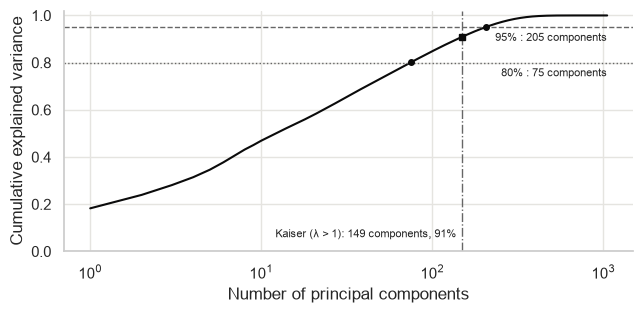

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
k = np.arange(1, len(var_cum) + 1)
ax.plot(k, var_cum, color=ENCRE, linestyle="-", marker="")
for s, style in ((0.8, ":"), (0.95, "--")):
    n = np.searchsorted(var_cum, s) + 1
    ax.axhline(s, color="0.4", linestyle=style, linewidth=1, marker="")
    ax.plot(n, var_cum[n - 1], color=ENCRE, marker="o", linestyle="")
    ax.annotate(f"{s:.0%} : {n} components", (len(k), s), xytext=(0, -4),
                textcoords="offset points", ha="right", va="top", fontsize=8)
ax.axvline(n_kaiser, color="0.4", linestyle="-.", linewidth=1, marker="")
ax.plot(n_kaiser, var_cum[n_kaiser - 1], color=ENCRE, marker="s", linestyle="")
ax.annotate(f"Kaiser (λ > 1): {n_kaiser} components, {var_cum[n_kaiser - 1]:.0%}",
            (n_kaiser, 0.05), xytext=(-4, 0), textcoords="offset points",
            ha="right", va="bottom", fontsize=8)
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance",
       ylim=(0, 1.02), xscale="log")
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_variance_acp.png", dpi=300, bbox_inches="tight")
plt.show()